# Options

In [7]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

L_arr = [6]
# L_arr = [16]
J = 1
h = 0.05
lamb = 0.7
g = 10

comp_uncomp_cal = True

x_basis = False

particle_pair_left_positions = [L//2 - 1 for L in L_arr]
particle_pair_length = 1

final_time = 8
steps = 35

shots = 50000

jobs_result_folder = "Results/"

circ_folder_path = "Circuits/"

# Noise model

In [8]:
from cobos.tokens import ibm_token, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer.noise import NoiseModel
from qiskit_aer import AerSimulator

device = "ibm_fez"
eplg_absolute = 4.74e-3

barriers = False

service = QiskitRuntimeService(channel="ibm_quantum", token=ibm_token, instance=group_instance2)
backend = service.backend(device)
fake_backend = AerSimulator.from_backend(backend)

sampler_options = {
    "default_shots": shots,
    # "execution": {
    #     "init_qubits": True,
    #     "meas_type": "classified"
    # },
    # "dynamical_decoupling": {
    #     "enable": False,
    #     "sequence_type": "XY4"
    # },
    # "twirling": {
    #     "enable_gates": False,
    #     "enable_measure": False,
    #     "num_randomizations": "auto",
    #     "shots_per_randomization": "auto"
    # }
}

noise_model = NoiseModel.from_backend(backend)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_49214/165263083.py:13: DeprecationWarning: The class ``qiskit.providers.models.backendconfiguration.QasmBackendConfiguration`` is deprecated as of qiskit 1.2. It will be removed in the 2.0 release. The models in ``qiskit.providers.models`` are part of the deprecated `BackendV1` workflow and no longer necessary for `BackendV2`. If a user workflow requires these representations it likely relies on deprecated functionality and should be updated to use `BackendV2`.
  fake_backend = AerSimulator.from_backend(backend)


# Full circuit

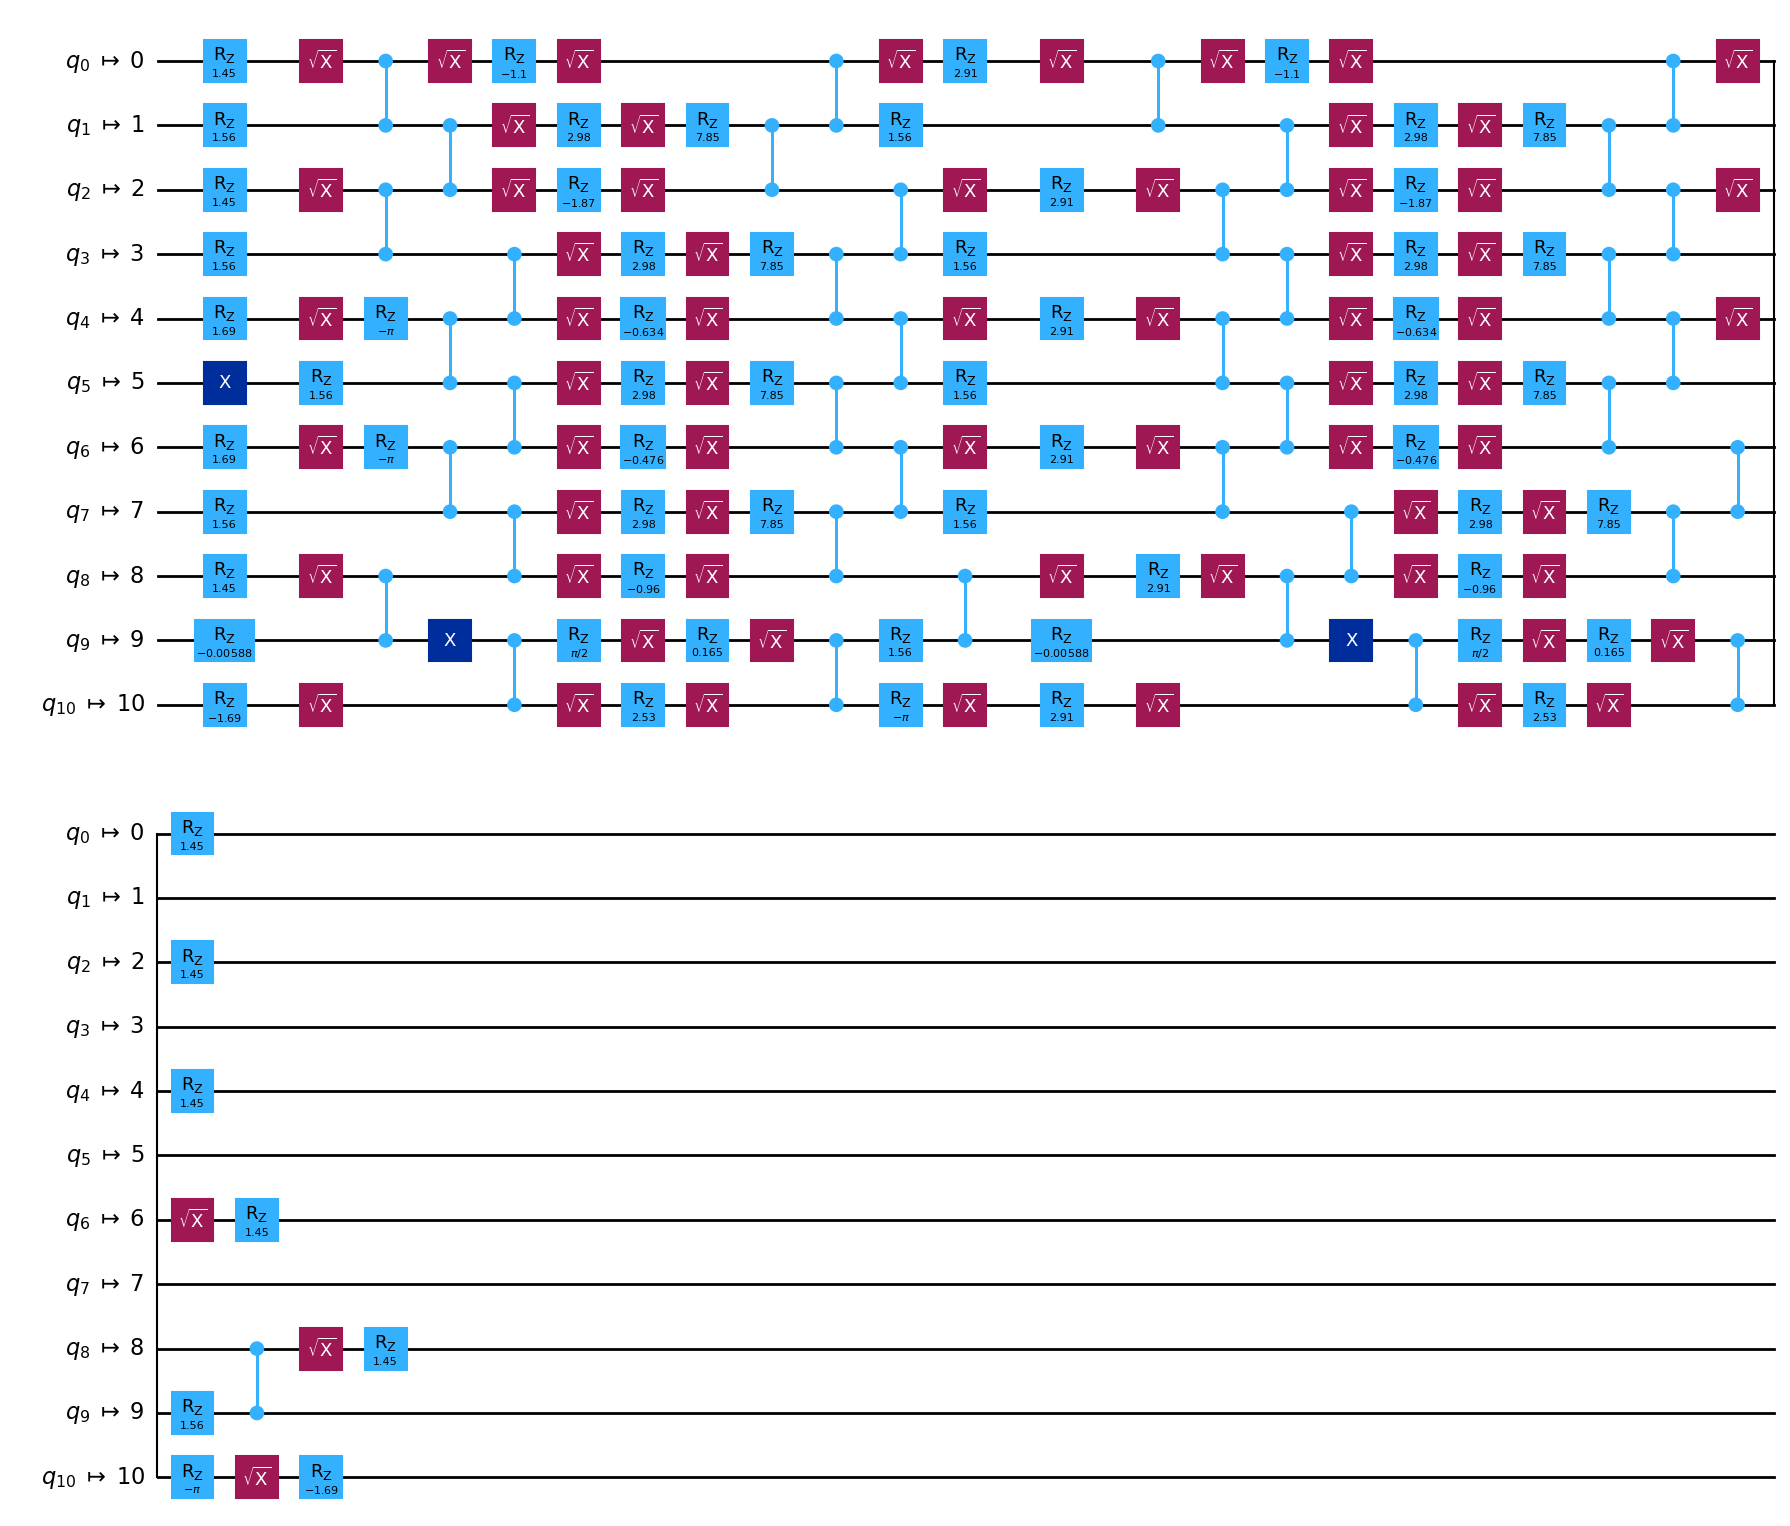

In [9]:
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from z2chain.circs import erradj_particle_pair_quench_simulation_circuits
from utils.circs import generate_and_save_circs, remove_idle_qwires
from functools import partial
import numpy as np
import os

optimization_level = 2

circuits_full = [] # circuits[L][t]
observable_generating_funcs_full = [] #observable_generating_funcs[L][i]
postselection_operators_funcs_full = []

estimator_options = {
    "default_precision": 1e-5
}

simulator_options = {
    "method": "statevector"
}

eplg_absolute = 2e-3

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    circuit_filepath = os.path.join(circ_folder_path, f"z2chain_quench_circs_simulation_{device}_maxt_{final_time}_steps_{steps}_L_{L}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_pp_{pp_ps}_pl_{particle_pair_length}_xbasis_{x_basis}.qpy")
    qubits_inds = np.arange(2*L-1)
    circs_func_args = (L, J, h, lamb, pp_ps, particle_pair_length, final_time, steps, backend, optimization_level, eplg_absolute, g, qubits_inds, x_basis, True)
    circuit = generate_and_save_circs(circuit_filepath, erradj_particle_pair_quench_simulation_circuits, *circs_func_args)
    circuits_full.append(circuit)
    observable_generating_funcs_full.append([partial(local_pauli_z if not x_basis else local_pauli_x, qubit_ind=i) for i in range(2*L-1)])
    postselection_operators_funcs_full.append(lambda nqubits: postselection_operators((nqubits + 1)//2, x_basis))

circuits_full[0][1].draw(output="mpl", idle_wires=False)

# Calibration circuit

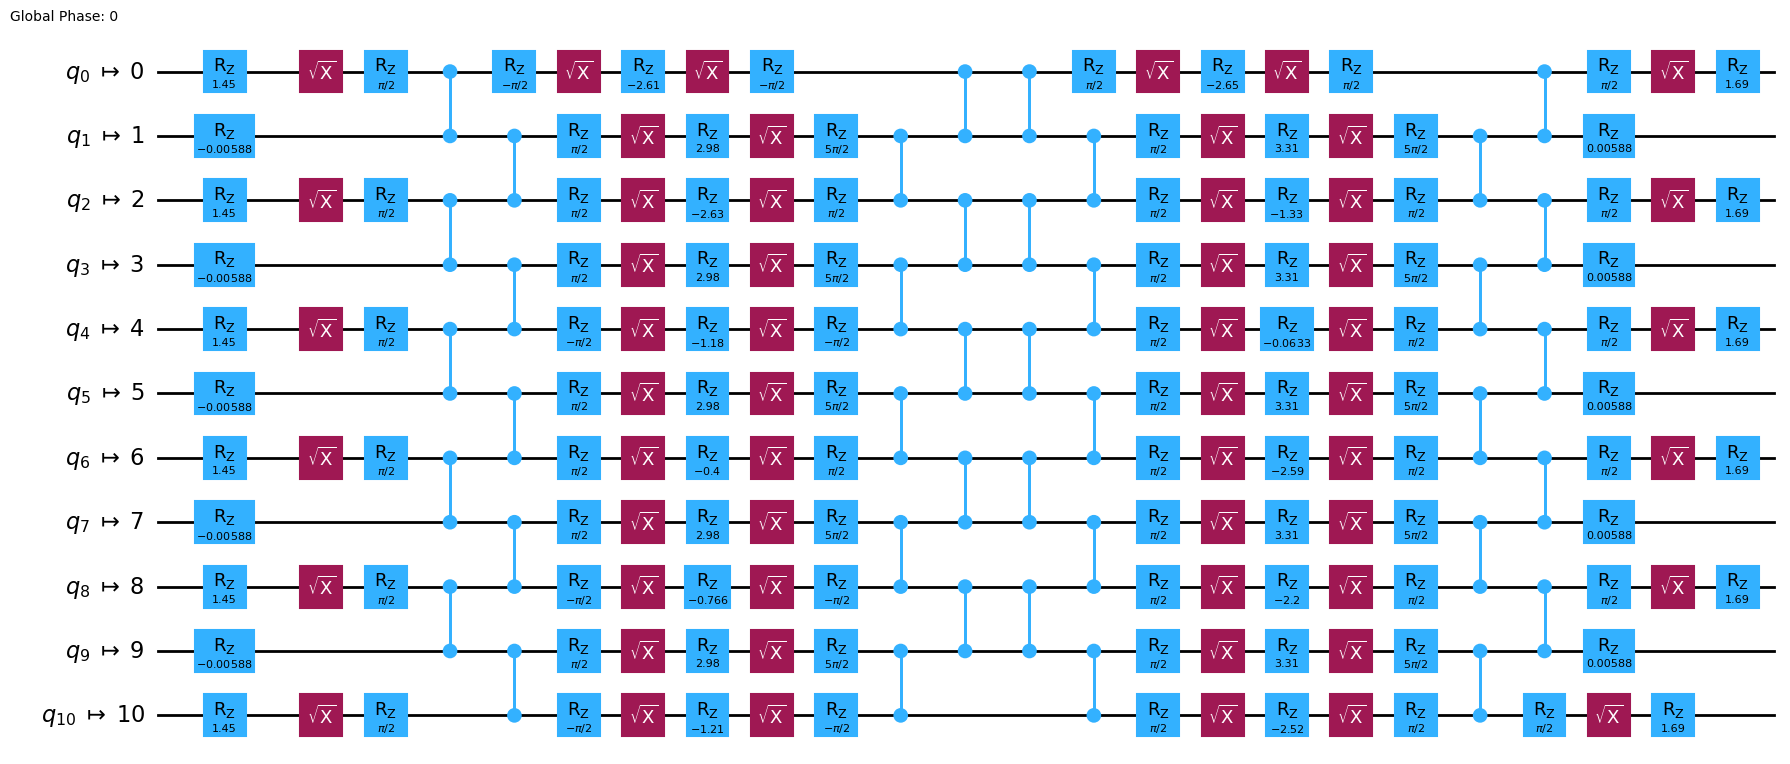

In [10]:
from z2chain.circs import erradj_particle_pair_quench_simulation_circuits, odr_forward_circuits, odr_compuncomp_circuits
from utils.circs import generate_and_save_circs, remove_idle_qwires
from z2chain.operators import local_pauli_x, local_pauli_z
from functools import partial
import numpy as np
import os

optimization_level = 2

circuits_cal = [] # circuits[L][t]
observable_generating_funcs_cal = [] #observable_generating_funcs[L][i]
postselection_operators_funcs_cal = []

estimator_options = {
    "default_precision": 1e-5
}

simulator_options = {
    "method": "density_matrix",
    "noise_model": noise_model
}

eplg_absolute = 2e-3

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    circuit_filepath = os.path.join(circ_folder_path, f"z2chain_quench_cal_circs_simulation_{device}_maxt_{final_time}_steps_{steps}_L_{L}_g_{g}_pp_ps_{particle_pair_left_positions}_pp_len_{particle_pair_length}_xbasis_{x_basis}.qpy")
    qubits_inds = np.arange(2*L-1)
    # circs_func_args = (L, final_time, steps, backend, eplg_absolute, g, qubits_inds, x_basis, True)
    # circuit = generate_and_save_circs(circuit_filepath, odr_forward_circuits, *circs_func_args)
    circuit = odr_compuncomp_circuits(L, J, h, lamb, final_time, steps, backend, eplg_absolute, g=g, particle_pair_left_position=pp_ps, particle_pair_length=particle_pair_length, layout=qubits_inds, x_basis=False)
    circuits_cal.append(circuit)
    observable_generating_funcs_cal.append([partial(local_pauli_z if not x_basis else local_pauli_x, qubit_ind=i) for i in range(2*L-1)])
    postselection_operators_funcs_cal.append(lambda nqubits: postselection_operators((nqubits + 1)//2, x_basis))

circuits_cal[0][1].draw(output="mpl", idle_wires=False)

# Simulation of Noisy circuits & ODR

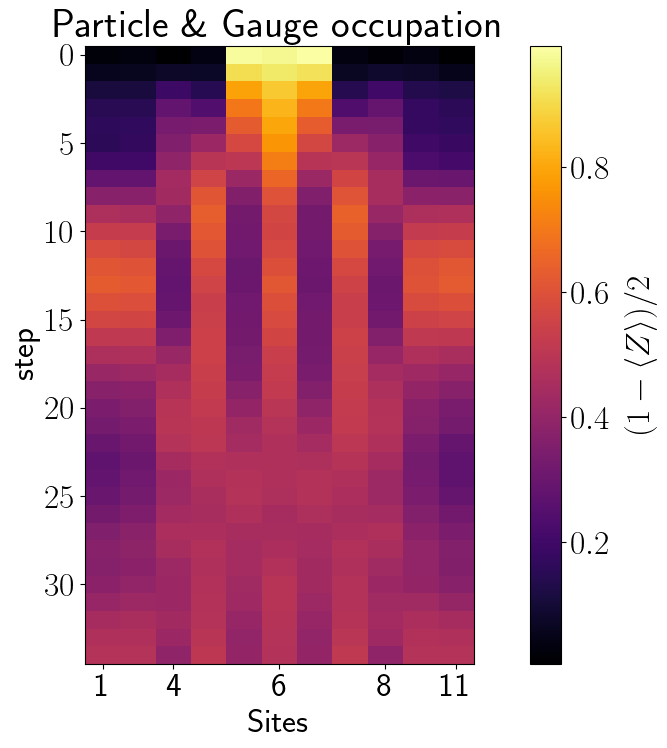

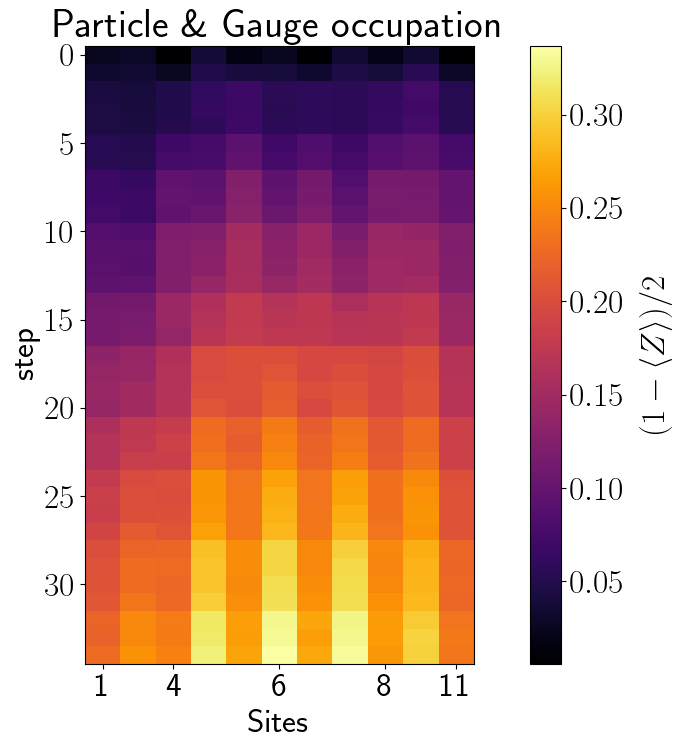

In [11]:
from utils.postselection import simulate_postselected_operators
from utils.hexec import execute_estimator_batch
from z2chain.plotting import x_t_plot
import json
import os

for i, L in enumerate(L_arr):
    filepath_full = os.path.join(jobs_result_folder, f"z2chain_quench_noisy_postselection_simulation_{device}_L_{L}_maxt_{final_time}_steps_{steps}.json")
    filepath_cal = os.path.join(jobs_result_folder, f"z2chain_quench_cal_circs_postselection_simulation_{device}_L_{L}_maxt_{final_time}_steps_{steps}.json")
    if os.path.exists(filepath_full):
        with open(filepath_full, "r") as f:
            data_full = json.load(f)
        data_full[0] = np.array(data_full[0])
    else:
        data_full = simulate_postselected_operators(fake_backend, sampler_options, circuits_full[i], postselection_operators_funcs_full[i], observable_generating_funcs_full[i], return_samples_dicts=True, return_postselected_samples_dicts=True)
        with open(filepath_full, "w") as f:
            data_full_file = data_full.copy()
            data_full_file[0] = data_full_file[0].tolist()
            json.dump(data_full_file, f)
    if os.path.exists(filepath_cal):
        with open(filepath_cal, "r") as f:
            data_cal = json.load(f)
        data_cal[0] = np.array(data_cal[0])
    else:
        data_cal = simulate_postselected_operators(fake_backend, sampler_options, circuits_cal[i], postselection_operators_funcs_cal[i], observable_generating_funcs_cal[i], return_samples_dicts=True, return_postselected_samples_dicts=True)
        # data_cal = [execute_estimator_batch(fake_backend, )]
        with open(filepath_cal, "w") as f:
            data_cal_file = data_cal.copy()
            data_cal_file[0] = data_cal_file[0].tolist()
            json.dump(data_cal_file, f)
    occupations_full = (1 - data_full[0]) / 2
    occupations_cal = (1 - data_cal[0]) / 2
    x_t_plot(occupations_full)
    x_t_plot(occupations_cal)

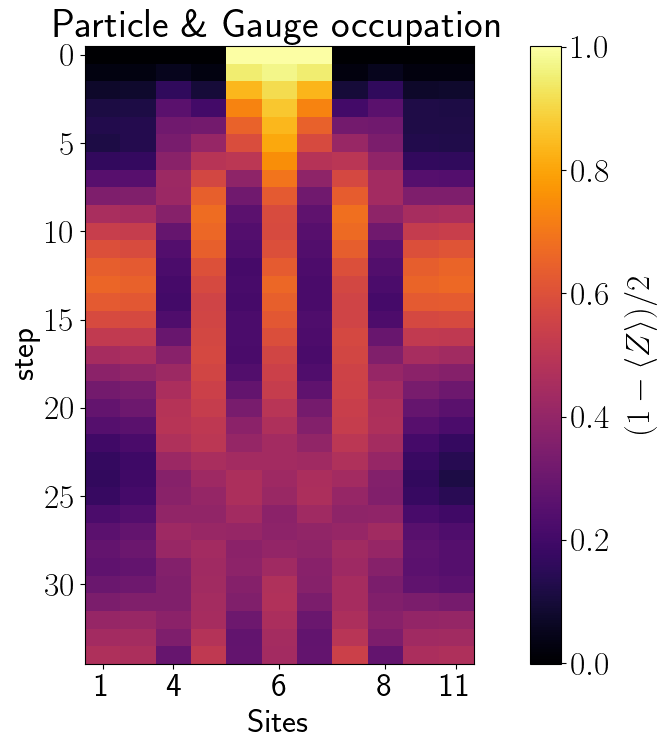

In [12]:
from utils.odr import compute_depolarizing_probability, renormalize_observable

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    expected_odr_observable = np.zeros(2*L-1)
    expected_odr_observable[pp_ps:pp_ps+2*pp_ps+1] = 1
    p_arr = compute_depolarizing_probability(data_cal[0], 1, expected_odr_observable, 2*L-1)
    pauli_clean = renormalize_observable(data_full[0], p_arr, 0, 2*L-1)
    occupations_clean = (1 - pauli_clean) / 2
    x_t_plot(occupations_clean)